# Drug Classification using Random Forest
In this section, we will load the `drug200.csv` dataset, perform preprocessing, split the data, and train a Random Forest classifier.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Load the dataset
df = pd.read_csv('/content/sample_data/drug200.csv')
display(df.head())

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,DrugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,DrugY


### Preprocessing
We need to encode the categorical variables (`Sex`, `BP`, `Cholesterol`, and the target `Drug`) before training the Random Forest model.

In [2]:
# Check for missing values
print("Missing Values:\n", df.isnull().sum())

# Encode categorical features
label_encoders = {}
categorical_cols = ['Sex', 'BP', 'Cholesterol']

for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

# Encode target variable 'Drug'
target_encoder = LabelEncoder()
df['Drug'] = target_encoder.fit_transform(df['Drug'])

# Split features and target
X = df.drop('Drug', axis=1)
y = df['Drug']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Missing Values:
 Age            0
Sex            0
BP             0
Cholesterol    0
Na_to_K        0
Drug           0
dtype: int64
Training set shape: (160, 5)
Testing set shape: (40, 5)


### Model Training and Evaluation
Now, we train a `RandomForestClassifier` and evaluate it with a classification report and a confusion matrix.

Model Accuracy: 100.00%

Classification Report:
              precision    recall  f1-score   support

       DrugY       1.00      1.00      1.00        15
       drugA       1.00      1.00      1.00         6
       drugB       1.00      1.00      1.00         3
       drugC       1.00      1.00      1.00         5
       drugX       1.00      1.00      1.00        11

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



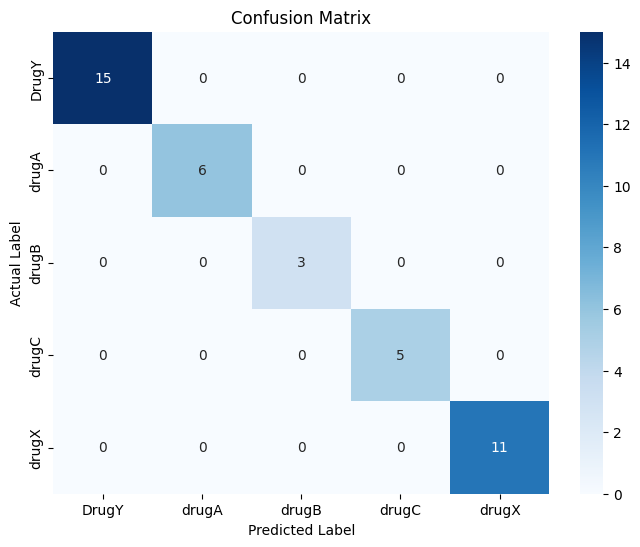

In [3]:
# Train the Random Forest model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predict on the test set
y_pred = rf_model.predict(X_test)

# Evaluate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")

# Display classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=target_encoder.classes_))

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=target_encoder.classes_, yticklabels=target_encoder.classes_)
plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

### Feature Importance
Let's see which features played the most important role in the model's decisions.

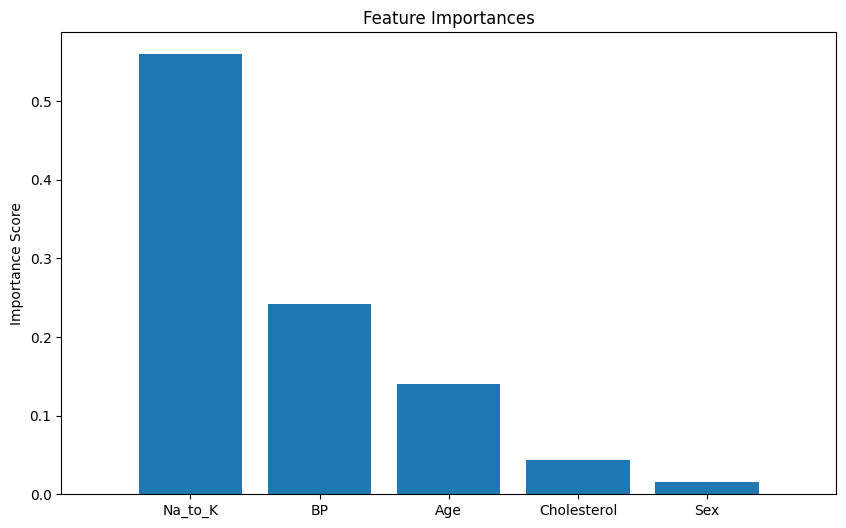

In [4]:
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]
features = X.columns

plt.figure(figsize=(10, 6))
plt.title("Feature Importances")
plt.bar(range(X.shape[1]), importances[indices], align="center")
plt.xticks(range(X.shape[1]), [features[i] for i in indices])
plt.xlim([-1, X.shape[1]])
plt.ylabel("Importance Score")
plt.show()

## Pipeline-based Random Forest Drug Classification Model
Here we implement a robust pipeline using `ColumnTransformer`, `OneHotEncoder`, and `Pipeline` from `scikit-learn` with stratified splitting.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Separate inputs and targets
X_pipe = df.drop('Drug', axis=1, errors='ignore')
# Reloading raw dataframe if needed to keep categoricals original
raw_df = pd.read_csv('/content/sample_data/drug200.csv')
X_raw = raw_df.drop('Drug', axis=1)
y_raw = raw_df['Drug']

# Identify categorical and numerical columns
categorical_columns = X_raw.select_dtypes(include=['object']).columns
numerical_columns = X_raw.select_dtypes(exclude=['object']).columns

# Set up preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns),
        ('num', 'passthrough', numerical_columns)
    ]
)

# Split dataset using stratification
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=42, stratify=y_raw
)

# Setup the pipeline
pipeline_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

# Train the pipeline model
pipeline_model.fit(X_train_p, y_train_p)
print("Pipeline training complete!")

Pipeline training complete!


In [6]:
# Predict and evaluate
y_pred_p = pipeline_model.predict(X_test_p)
print(f"Pipeline Model Accuracy: {accuracy_score(y_test_p, y_pred_p) * 100:.2f}%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_p, y_pred_p))

print("\nClassification Report:")
print(classification_report(y_test_p, y_pred_p))

Pipeline Model Accuracy: 97.50%

Confusion Matrix:
[[18  0  0  0  0]
 [ 0  5  0  0  0]
 [ 0  0  3  0  0]
 [ 0  0  0  3  0]
 [ 1  0  0  0 10]]

Classification Report:
              precision    recall  f1-score   support

       DrugY       0.95      1.00      0.97        18
       drugA       1.00      1.00      1.00         5
       drugB       1.00      1.00      1.00         3
       drugC       1.00      1.00      1.00         3
       drugX       1.00      0.91      0.95        11

    accuracy                           0.97        40
   macro avg       0.99      0.98      0.99        40
weighted avg       0.98      0.97      0.97        40



,Feature,Importance
8,num__Na_to_K,0.518633
7,num__Age,0.133694
2,cat__BP_HIGH,0.115213
4,cat__BP_NORMAL,0.066849
3,cat__BP_LOW,0.054447
6,cat__Cholesterol_NORMAL,0.050624
5,cat__Cholesterol_HIGH,0.035673
0,cat__Sex_F,0.012830
1,cat__Sex_M,0.012036


/tmp/ipykernel_576/1250827706.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')


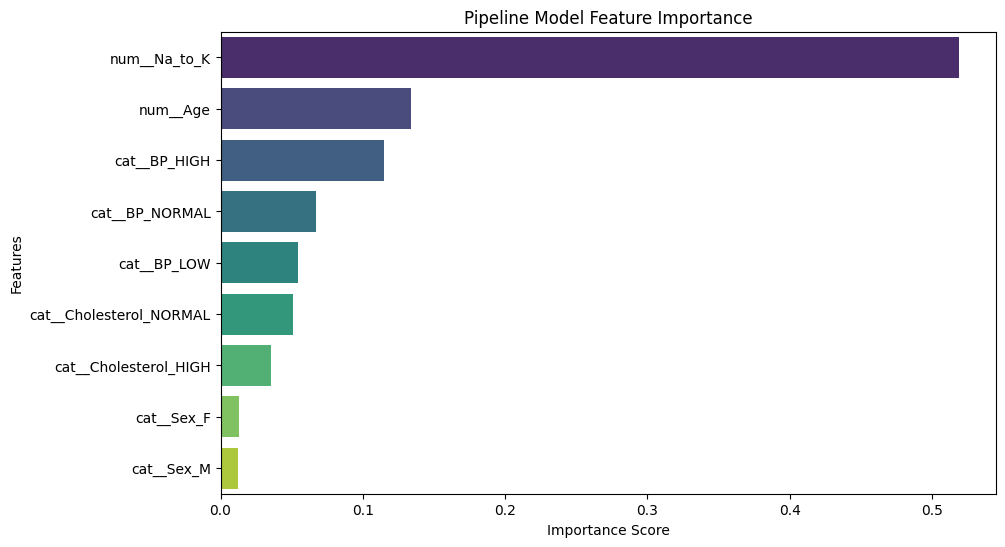

In [7]:
# Retrieve feature importances from pipeline
feature_names = pipeline_model.named_steps['preprocessor'].get_feature_names_out()
importances = pipeline_model.named_steps['classifier'].feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

display(feature_importance_df)

# Plotting Pipeline feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')
plt.title('Pipeline Model Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

## Drug Dataset - Random Forest Regression
In this section, we build a regression pipeline using `RandomForestRegressor` to predict the continuous feature `Na_to_K` based on age, sex, blood pressure, cholesterol, and drug type.

In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Prepare features and target for regression
# Target: Na_to_K (continuous)
# Features: Age, Sex, BP, Cholesterol, Drug
X_reg = raw_df.drop('Na_to_K', axis=1)
y_reg = raw_df['Na_to_K']

# Identify categorical and numerical columns for regression
categorical_cols_reg = X_reg.select_dtypes(include=['object']).columns
numerical_cols_reg = X_reg.select_dtypes(exclude=['object']).columns

# Setup preprocessor for regression
preprocessor_reg = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols_reg),
        ('num', 'passthrough', numerical_cols_reg)
    ]
)

# Train-test split
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

# Define the Regression Pipeline
reg_pipeline = Pipeline([
    ('preprocessor', preprocessor_reg),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

# Train the regressor
reg_pipeline.fit(X_train_reg, y_train_reg)
print("Regression model training complete!")

Regression model training complete!


Mean Squared Error (MSE): 15.3773
R-squared (R2 Score): 0.6935


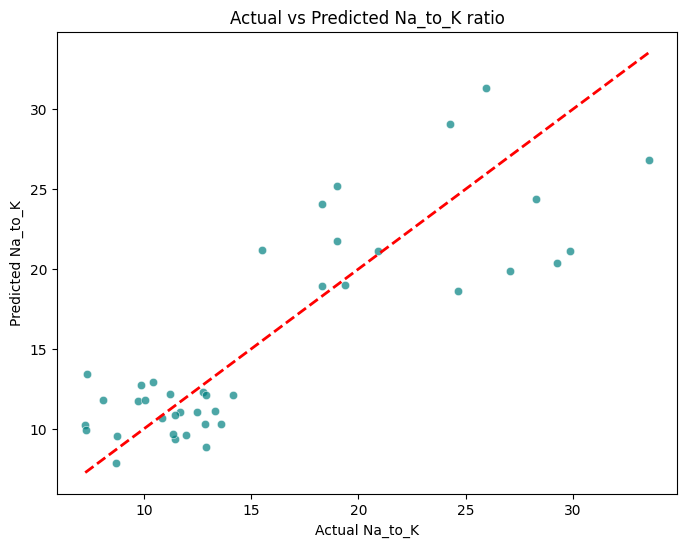

In [9]:
# Predict and evaluate the regression model
y_pred_reg = reg_pipeline.predict(X_test_reg)

mse = mean_squared_error(y_test_reg, y_pred_reg)
r2 = r2_score(y_test_reg, y_pred_reg)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-squared (R2 Score): {r2:.4f}")

# Plot actual vs predicted values
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test_reg, y=y_pred_reg, color='teal', alpha=0.7)
plt.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--', lw=2)
plt.title('Actual vs Predicted Na_to_K ratio')
plt.xlabel('Actual Na_to_K')
plt.ylabel('Predicted Na_to_K')
plt.show()